In [46]:

import pandas as pd
import numpy as np
from glob import glob
import datetime as dt
import matplotlib.pyplot as plt
import pendulum as pdl
import seaborn as sns
import scipy.stats as stats

# Load the data - 03_tiltmeter
This script loads the data form the reference undamaged state of OpenLAB and visualize them

In [30]:
def read_csv_files(pth, separated: bool = False):
    """
    Read all CSV files in a directory and return a single DataFrame.
    If separated is True, each file is read separately and then concatenated.
    If separated is False, all files are read at once.
    """
    # all files in the directory
    files = glob(pth + '/*.csv')
    dfs = [pd.read_csv(file) for file in files]
    if separated:
        return dfs
    df = pd.concat(dfs, ignore_index=True)
    return df

pth = "OpenLAB_Data/2024-02-01_2024-10-31_ida_ki_export/03_tiltmeter"
df = read_csv_files(pth, separated=False) 


In [31]:
color_map = ...
def plot_data(df, df2: pd.DataFrame = None, prediction: pd.DataFrame = None, settings: dict = {}, **kwargs):
    
    df=df.copy()
    df2=df2.copy() if df2 is not None else None
    prediction=prediction.copy() if prediction is not None else None
    #subtract the mean of the first 10 values from all the values to remove the offset
    # df[df.colu mns[2:]] -= df[df.columns[2:]][:10].mean() 
    
    plot = df.plot(x='Timestamp', subplots=settings.get("SUBPLOTS", True), figsize=kwargs.get("figsize", (20, 60)), colormap='tab20', marker='o', markersize=3, linestyle='--')  

    # rotate x-axis labels for better readability
    if settings.get("SUBPLOTS", True) is False:
        plot = [plot]

    for ax in plot:
            # ax.set_xlabel('Time [h]')
            # get the sensor name
            sensor_name = ax.legend().get_texts()[0].get_text()
            # add the predicted values to the graphs
            ax.legend(loc='upper left')
            try:
                snt = sensor_name.replace('X_', 'T_')
                snh = sensor_name.replace('X_', 'H_')
            except KeyError:
                snt = sensor_name.replace('Y_', 'T_')
                snh = sensor_name.replace('Y_', 'H_')

            if df2 is not None:
                if snt in df2.columns and settings.get("PLOT_TEMPERATURE", True):
                    x_values = df2['Timestamp']
                    x_values = pd.to_datetime(x_values)
                    y_valuest = np.abs(df2[snt])
                    ax3 = ax.twinx()
                    ax3.plot(x_values, y_valuest, color='orange', alpha=0.25, linestyle='--',  label='Temperature measured')
                    ax3.set_ylabel('Temperature [°C]') # mrad
                    ax3.legend(loc='upper right')
                if snh in df2.columns and settings.get("PLOT_HUMIDITY", True):
                    x_values = df2['Timestamp']
                    x_values = pd.to_datetime(x_values)
                    # y_valuesh = np.abs(df2[snh])
                    y_valuesh = np.abs(df2[snh])
                    # add another y-axis for the humidity values
                    ax2 = ax.twinx()
                    ax2.plot(x_values, y_valuesh, color='green', alpha=0.25, linestyle='--',  label='Humidity measured')
                    ax2.set_ylabel('Humidity [%]') # mrad
                    ax2.legend(loc='lower right')
                
            if prediction is not None:
                if sensor_name in prediction.columns and settings.get("PLOT_PREDICTION", True):
                    # convert to hours for better readability
                    x_values = prediction['timestamp'] 
                    x_values = pd.to_datetime(x_values)
                    y_values = np.abs(prediction[sensor_name])
                    # y_values *= 10 # TODO: remove this random scaler
                    ax.plot(x_values, y_values, color='red', linestyle='--', marker='o', markersize=3, label='Prediction')
                    ax.set_xticklabels(ax.get_xticks(), rotation=45)
                    ax.set_ylabel('Tilt [mm/m]') # mrad
                    ax.legend(loc='lower left')

/tmp/ipykernel_163833/2480764089.py:56: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(x_values, y_values, color='red', linestyle='--', marker='o', markersize=3, label='Prediction')
/tmp/ipykernel_163833/2480764089.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticks(), rotation=45)
/tmp/ipykernel_163833/2480764089.py:56: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(x_values, y_values, color='red', linestyle='--', marker='o', markersize=3, label='Prediction')
/tmp/ipykernel_163833/2480764089.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticks(),

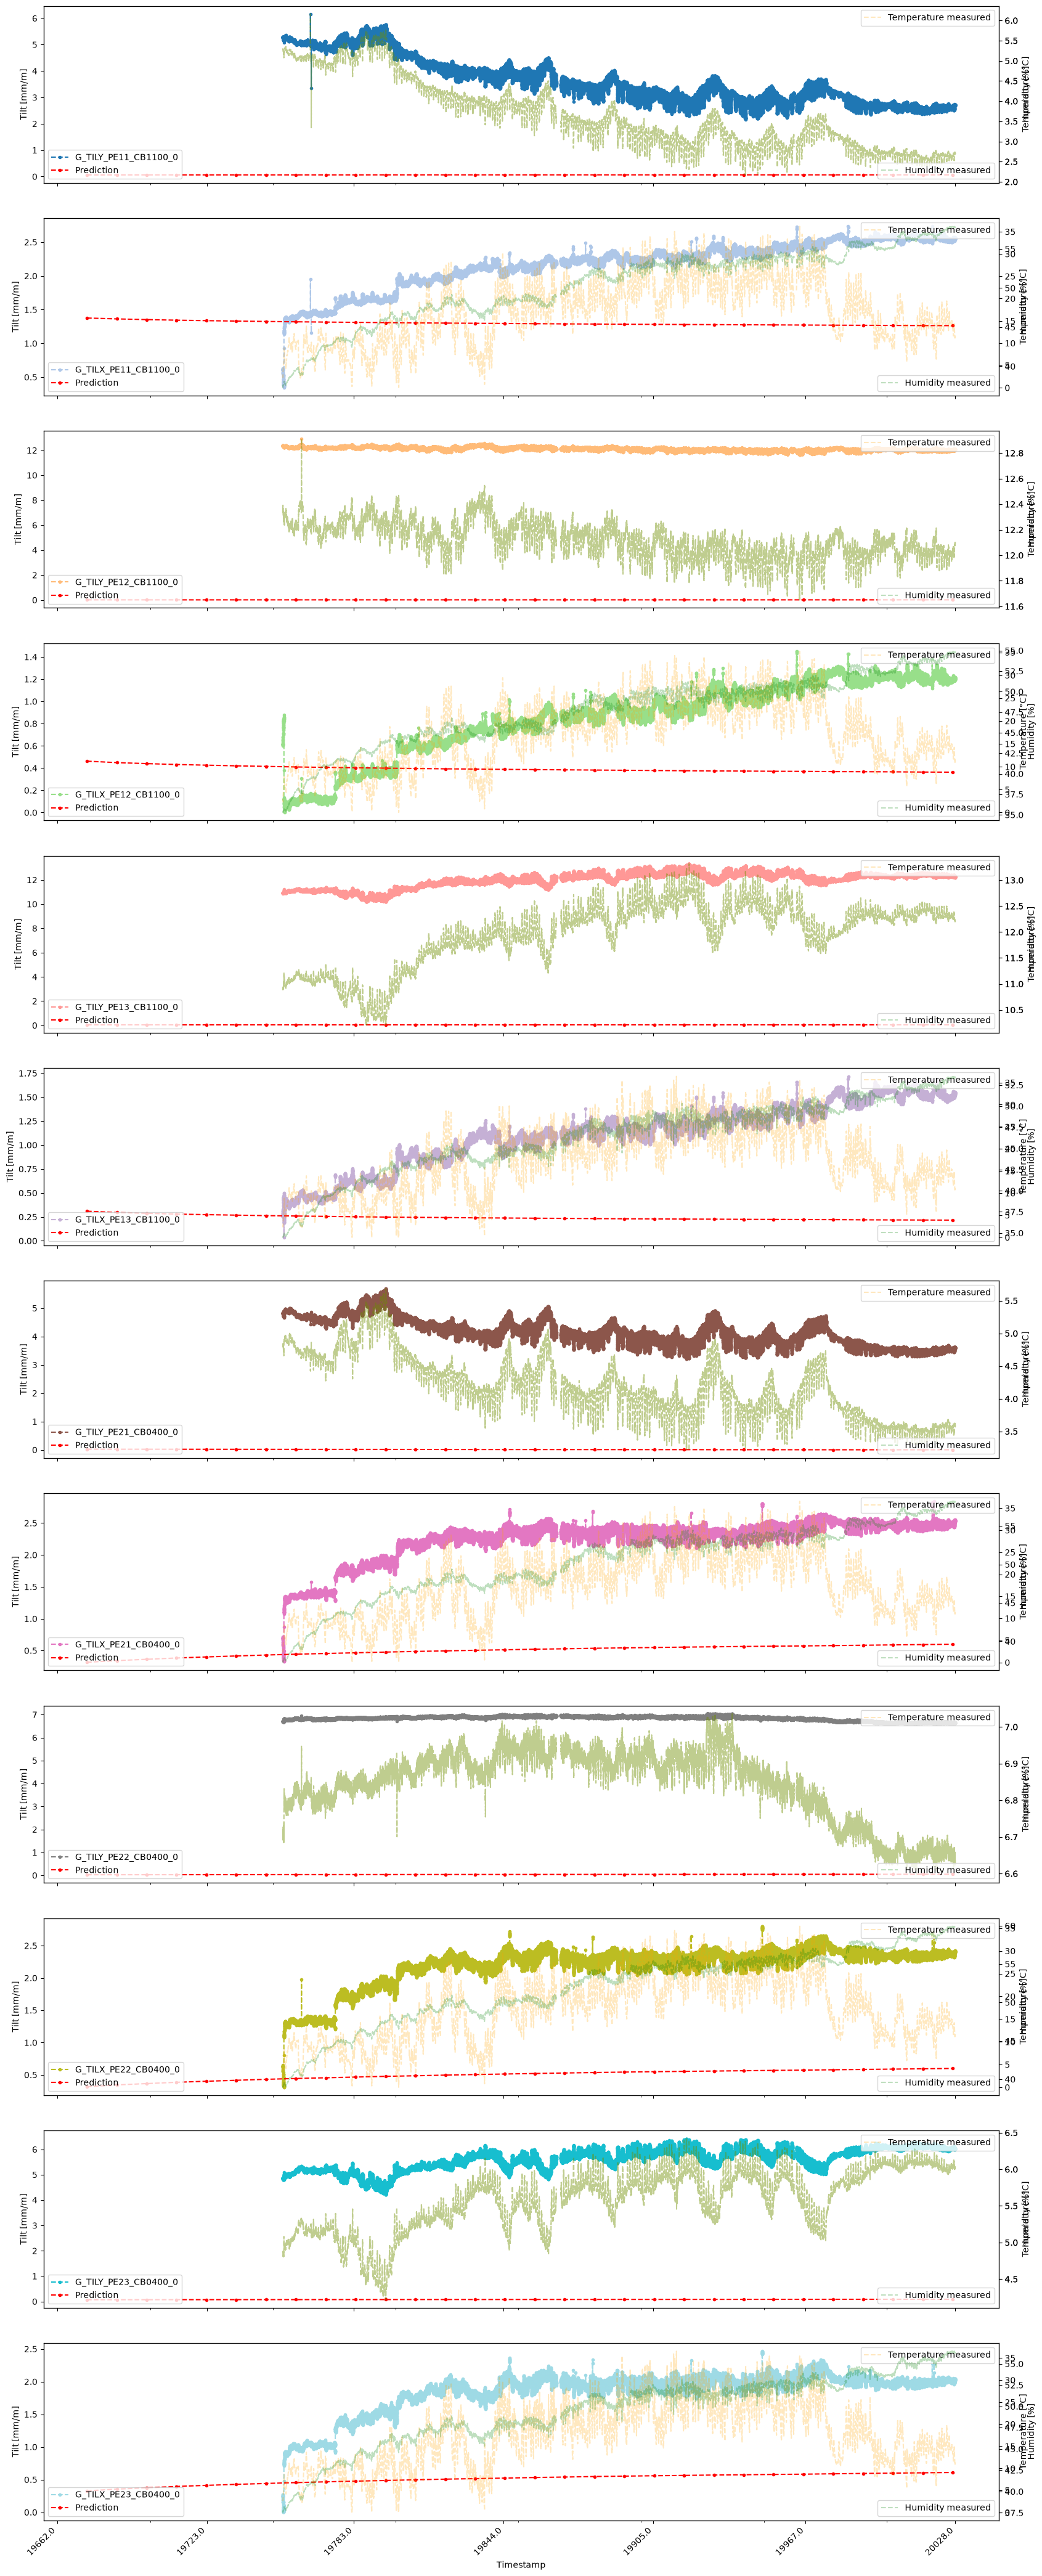

In [32]:
settings = {
    "SUBPLOTS": True,
    "PLOT_PREDICTION": True,
    "PLOT_TEMPERATURE": True,
    "PLOT_HUMIDITY": True
}

# add the predicted values to the graphs
prediction = pd.read_csv('tiltmeters_prediction.csv')
# True means separated plots for individual sensors
subplots = True  
# replace the pure zeros with NaN values, so that they are not plotted
df.replace(0, np.nan, inplace=True)
df1 = df.query('Timestamp < "2025-05-06 00:00:00"').copy()
df2 = df.query('Timestamp < "2025-05-06 00:00:00"').copy()

for col in df1.columns:
    if col == 'Timestamp':
        df1[col] = pd.to_datetime(df1[col])
    
    if "TILH" in col or "TILT" in col:
        # drop the columns that are not relevant for the analysis
        df1.drop(columns=col, inplace=True)

# plot the absolute values of the tiltmeters, as they are more relevant for the analysis
cols = df1.columns
for col in cols:
    if "TILX" in col or "TILY" in col:
        df1[col] = df1[col].abs()


plot_data(df1, df2, prediction, settings=settings)

In [33]:
# compute the correlation matrix between the tiltmeters and the temperature and humidity sensors
...

Ellipsis

In [34]:
kkey = 'G_TILH_PE13_CB1100_0'
# df1[kkey].max(), df2[kkey].min(), len(df2[kkey])
df[kkey].head()



0    34.515900
1    34.508270
2    34.500641
3    34.500641
4    34.485382
Name: G_TILH_PE13_CB1100_0, dtype: float64

# LOAD THE DATA - 03_tiltmeter - trigger 

In [35]:
pth = "OpenLAB_Data/2024-02-01_2024-10-31_ida_ki_export/04_tiltmeter_trigger"
# df = read_csv_files(pth)

dfs = read_csv_files(pth, separated=True)
dfs[0].head()

,Timestamp,G_TILX_PE11_CB1100_0,G_TILX_PE12_CB1100_0,G_TILX_PE13_CB1100_0,G_TILX_PE21_CB0400_0,G_TILX_PE22_CB0400_0,G_TILX_PE23_CB0400_0
0,2024-06-05 11:26:13.600,-0.019005,0.003867,-0.007708,-0.016340,0.006550,-0.004789
1,2024-06-05 11:26:13.800,-0.018782,0.003833,-0.007703,-0.016941,0.004825,-0.004053
2,2024-06-05 11:26:14.000,-0.018062,0.003698,-0.007678,-0.017783,0.002152,-0.002744
3,2024-06-05 11:26:14.200,-0.016330,0.003279,-0.007576,-0.018437,-0.000437,-0.001200
4,2024-06-05 11:26:14.400,-0.013094,0.002276,-0.007264,-0.018597,-0.002261,0.000172


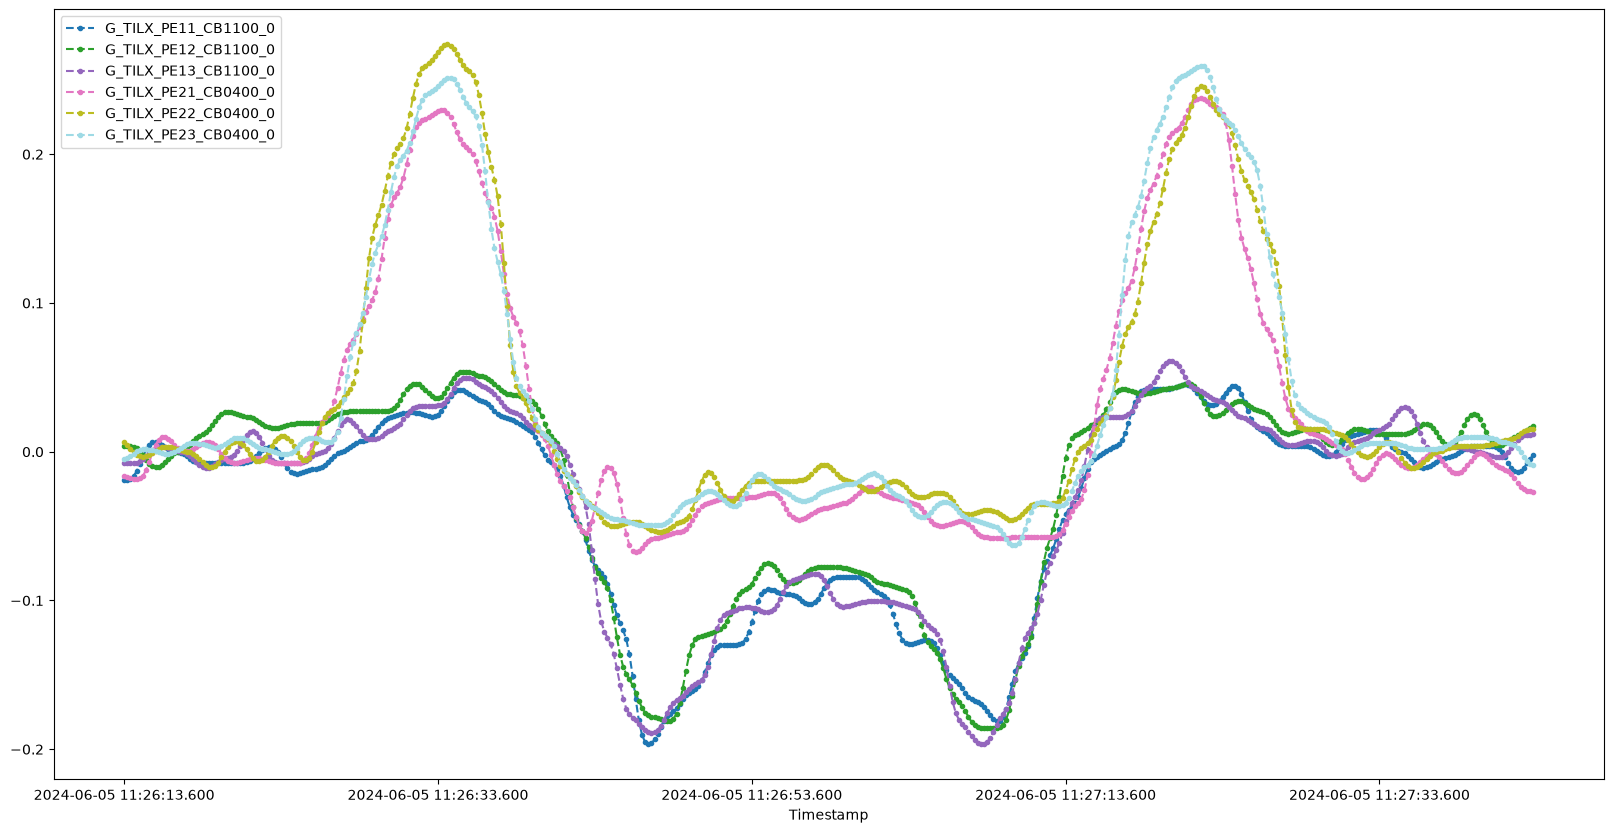

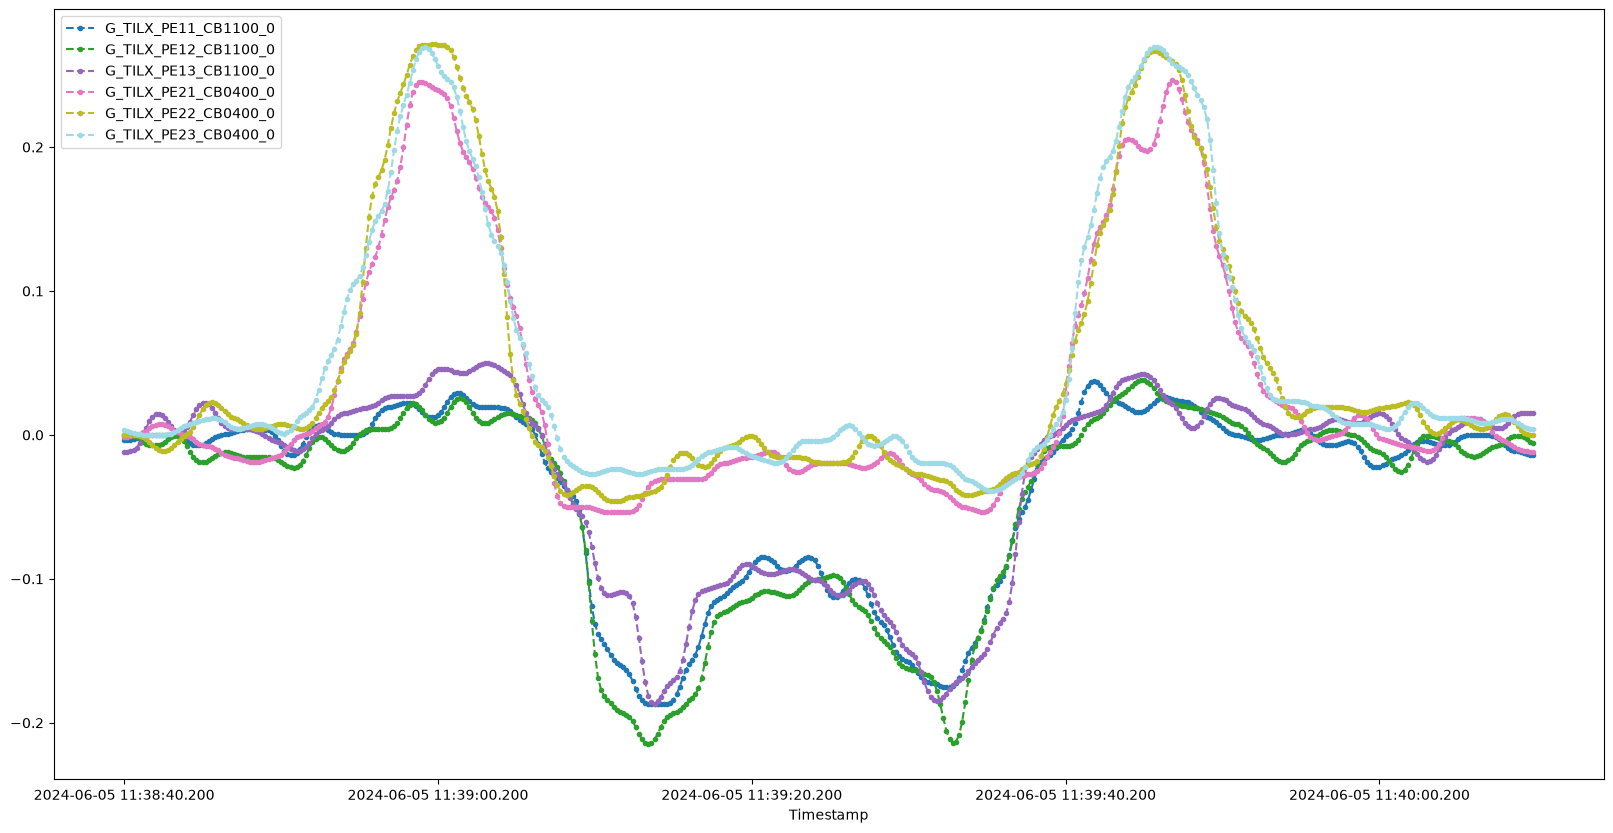

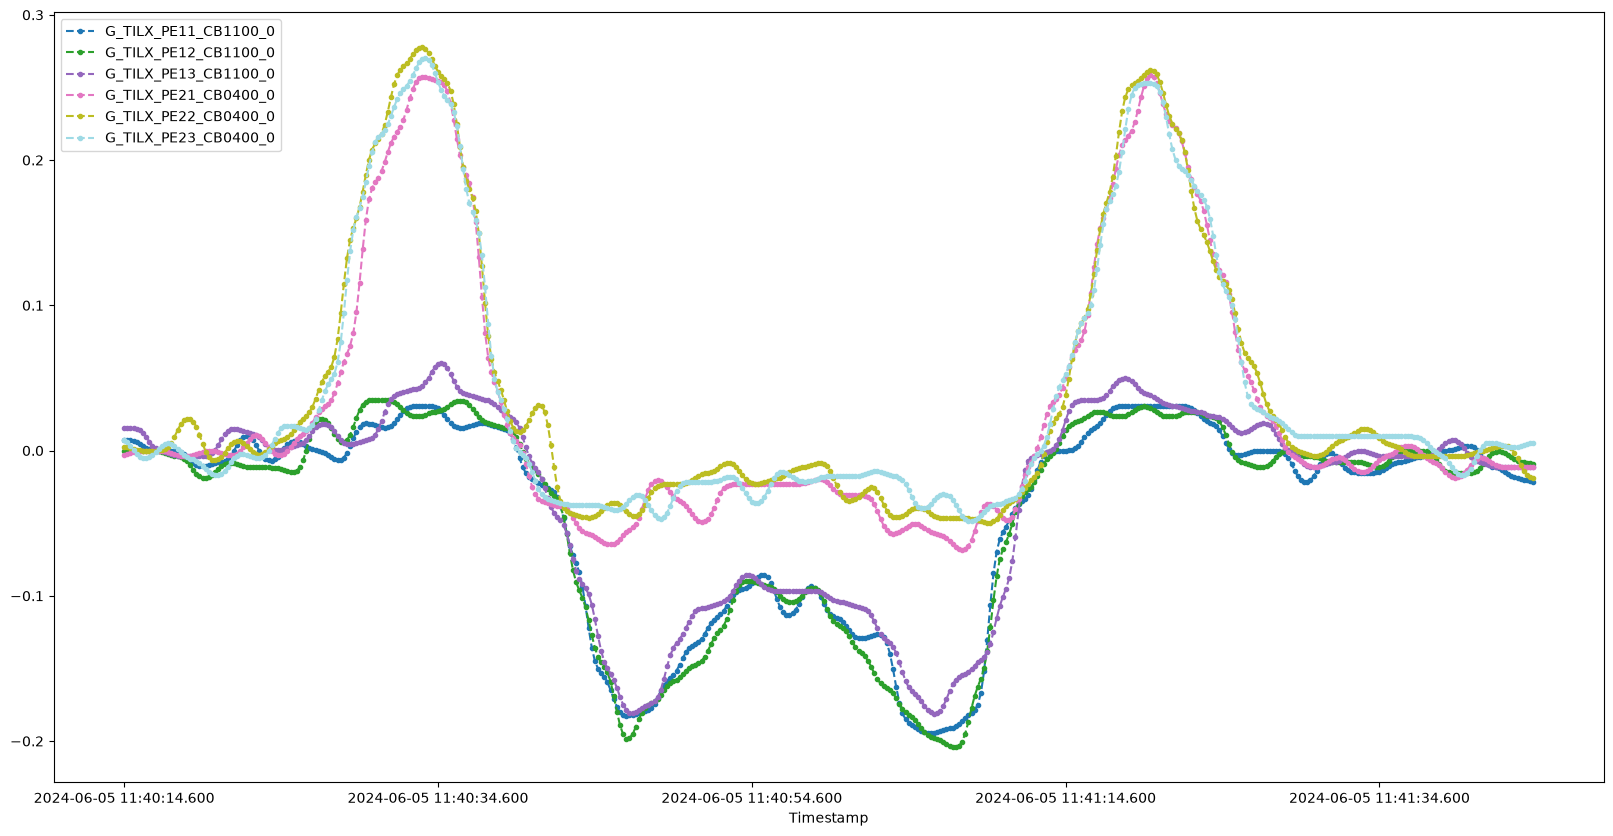

In [36]:
settings = {
    "SUBPLOTS": False,  
    "PLOT_PREDICTION": False,
    "PLOT_TEMPERATURE": False,
    "PLOT_HUMIDITY": False
}
# for i in range(len(dfs)):
for i in range(3):
    plot_data(dfs[i], settings=settings, figsize=(20, 10))

In [37]:
print("Assuming that all the dfs have the same length, WARNING RAISED OTHERWISE.")
len0 = len(dfs[0])
for i in range(len(dfs)):
    if len(dfs[i]) != len0:
        print(f"WARNING: Length of dfs[{i}] is different: {len(dfs[i])} != {len0}")

print("Assuming that all the dfs have the same duration, WARNING RAISED OTHERWISE.")
print(dfs[0]['Timestamp'].min(), dfs[0]['Timestamp'].max())
duration0 = pdl.parse(dfs[0]['Timestamp'].min()).diff(pdl.parse(dfs[0]['Timestamp'].max()))
for i in range(len(dfs)):
    duration = pdl.parse(dfs[i]['Timestamp'].min()).diff(pdl.parse(dfs[i]['Timestamp'].max()))
    if duration/duration0 != 1:
        print(f"WARNING: Duration of dfs[{i}] differs by: {duration - duration0}")
        print(duration/duration0)

Assuming that all the dfs have the same length, WARNING RAISED OTHERWISE.
Assuming that all the dfs have the same duration, WARNING RAISED OTHERWISE.
2024-06-05 11:26:13.600 2024-06-05 11:27:43.400


In [38]:
sensors_vehicle = dfs[0].columns
sensors_vehicle = sensors_vehicle[1:]
sensors_vehicle

Index(['G_TILX_PE11_CB1100_0', 'G_TILX_PE12_CB1100_0', 'G_TILX_PE13_CB1100_0',
       'G_TILX_PE21_CB0400_0', 'G_TILX_PE22_CB0400_0', 'G_TILX_PE23_CB0400_0'],
      dtype='str')

In [39]:
# since all the dfs have the same duration, we can group them and assume that the 1st timestamp is the df 0 corresponding to the 1st timestamp of all the other dfs.
# It is the same test, conducted at different times, but the steps are the same.
pseudo_timesteps = list(range(len(dfs[0])))

rows_1, rows_2 = [], []
split_date = pdl.parse("2024-06-27 00:00:00")  # Example split date for before and after 2024
for i in range(len(dfs)):
    before = pdl.parse(dfs[i]['Timestamp'].min()) < split_date
    for col in sensors_vehicle:    
        if col == "Timestamp":
            continue
        row = {"Sensor": col}
        row.update({
            timestep: value
            for timestep, value in zip(pseudo_timesteps, dfs[i][col].values)
        })
        if before:
            rows_1.append(row)
        else:
            rows_2.append(row)

df_grouped_1 = pd.DataFrame(rows_1, columns=["Sensor"] + pseudo_timesteps)
df_grouped_2 = pd.DataFrame(rows_2, columns=["Sensor"] + pseudo_timesteps)
df_grouped_1.head()
df_grouped_2.head()
df_grouped_1.Sensor.unique()

<StringArray>
['G_TILX_PE11_CB1100_0', 'G_TILX_PE12_CB1100_0', 'G_TILX_PE13_CB1100_0',
 'G_TILX_PE21_CB0400_0', 'G_TILX_PE22_CB0400_0', 'G_TILX_PE23_CB0400_0']
Length: 6, dtype: str

In [40]:
print(df_grouped_1.shape)
print(df_grouped_2.shape)

(54, 451)
(852, 451)


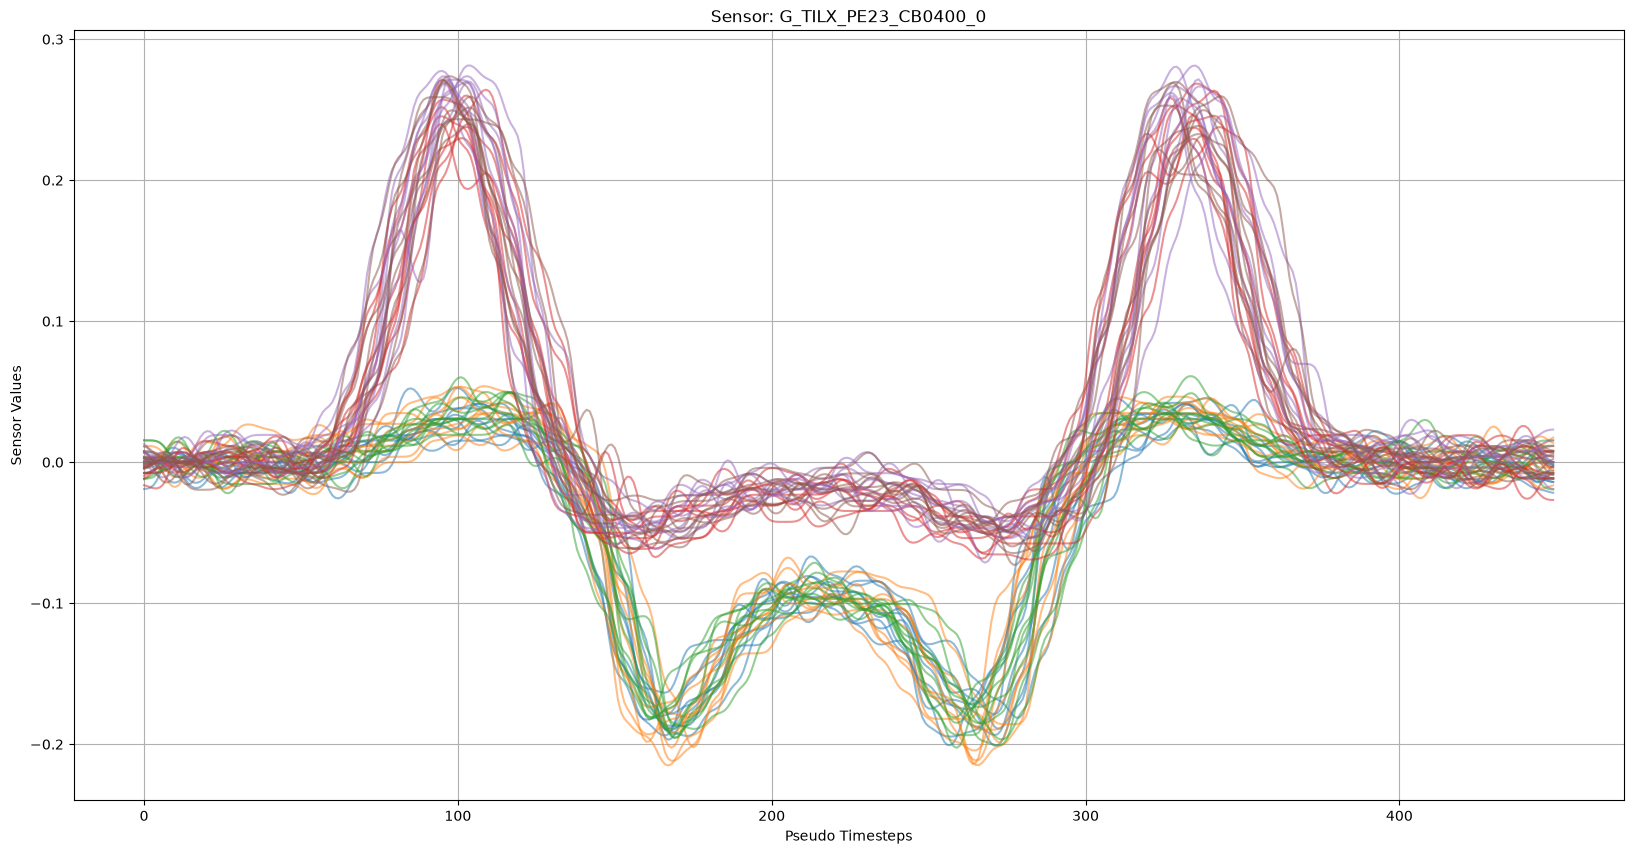

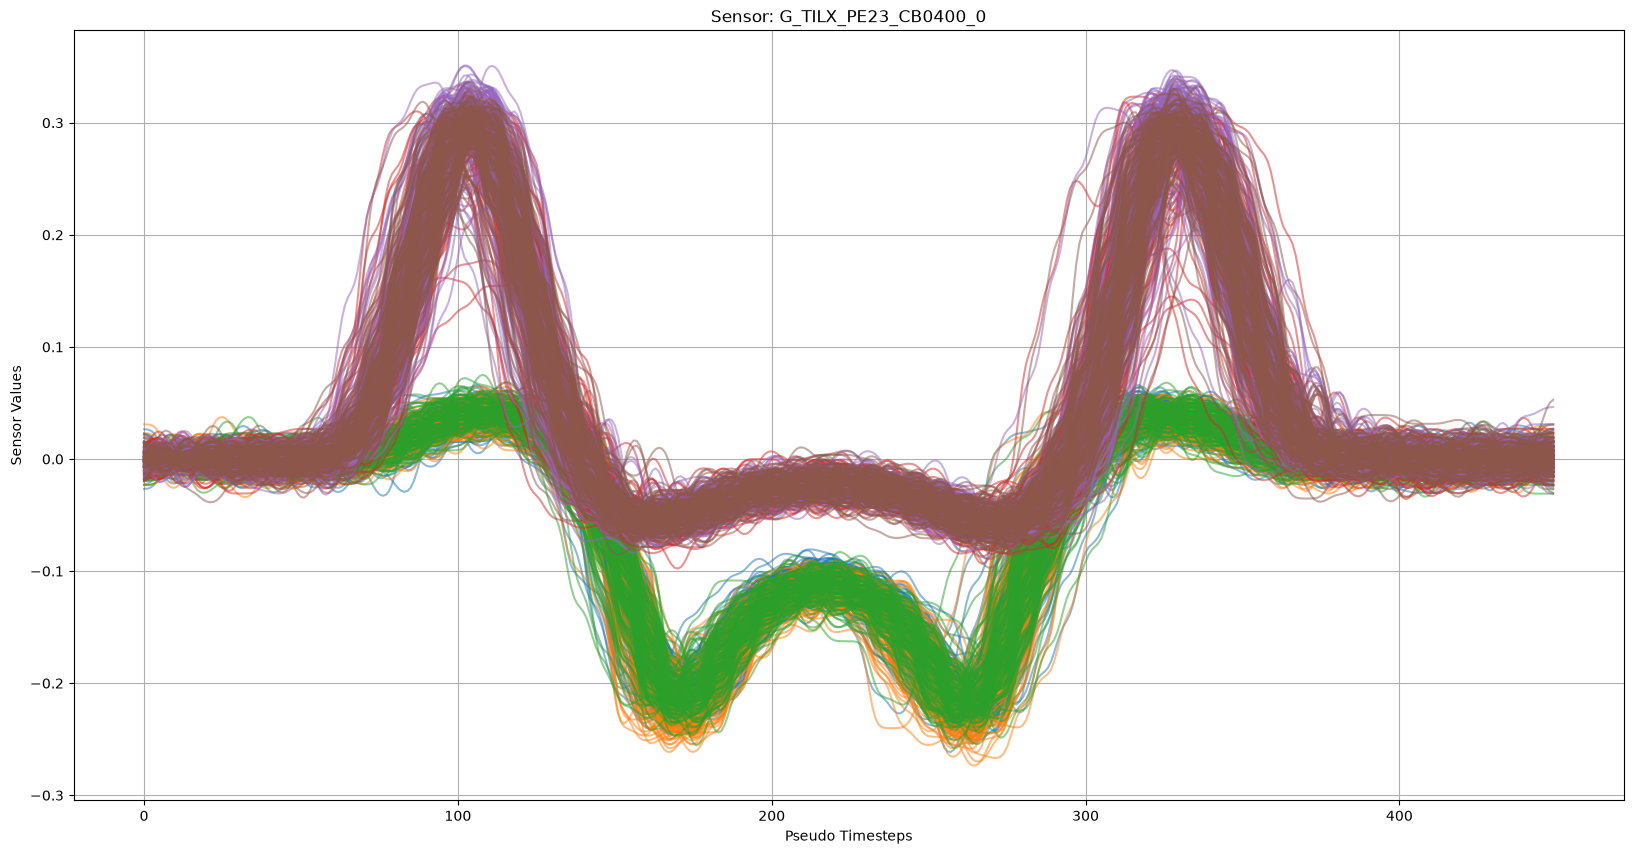

In [84]:
SEPARATED_PLOTS = False
colormap = sns.color_palette("tab10", n_colors=len(sensors_vehicle))
labels = sensors_vehicle

def plot_grouped_data(df_grouped, pseudo_timesteps, colormap, SEPARATED_PLOTS):
    if not SEPARATED_PLOTS:
        plt.figure(figsize=(20, 10))
        for i, sensor in enumerate(df_grouped.Sensor.unique()):
        # for i, sensor in enumerate([df_grouped.Sensor.unique()[1]]):
            if sensor == "Timestamp":
                continue
            plotdata = df_grouped.query(f"Sensor == '{sensor}'").T.to_numpy()
            plt.plot(
                np.arange(len(pseudo_timesteps)),
                plotdata[1:,:],
                label=sensor,
                color = colormap[i],
                alpha=0.5
            )
        plt.title(f"Sensor: {sensor}")
        plt.xlabel("Pseudo Timesteps")
        plt.ylabel("Sensor Values")
        # plt.legend()
        plt.grid()
        plt.show()
    else:
        for i, sensor in enumerate(df_grouped.Sensor.unique()):
            if sensor == "Timestamp":
                continue
            plt.figure(figsize=(20, 10))
            plotdata = df_grouped.query(f"Sensor == '{sensor}'").T.to_numpy()
            plt.plot(
                np.arange(len(pseudo_timesteps)),
                plotdata[1:,:],
                label=sensor,
                color = colormap[i],
                alpha=0.5,
            )
            plt.title(f"Sensor: {sensor}")
            plt.xlabel("Pseudo Timesteps")
            plt.ylabel("Sensor Values")
            # plt.legend()
            plt.grid()
            plt.show()
            
plot_grouped_data(df_grouped_1, pseudo_timesteps, colormap, SEPARATED_PLOTS)
plot_grouped_data(df_grouped_2, pseudo_timesteps, colormap, SEPARATED_PLOTS)


In [88]:
print(sensors_vehicle)
for col in sensors_vehicle:
    if col == "Timestamp":
        continue
    df1 = df_grouped_1.query(f"Sensor == '{col}'").T.to_numpy()[1:,:].flatten().astype(float)
    df2 = df_grouped_2.query(f"Sensor == '{col}'").T.to_numpy()[1:,:].flatten().astype(float)
    
    df1 = np.abs(df1)
    df2 = np.abs(df2)
    t_stat, p_value = stats.ttest_ind(df1, df2, equal_var=False)
    statistically_different = p_value < 0.05
    smaller_mean = min(np.mean(df1), np.mean(df2))
    means_difference = np.abs((np.mean(df1) - np.mean(df2))/smaller_mean)
    print(f"Sensor: {col}, t-statistic: {t_stat:.4f}, p-value: {p_value:.4f}")
    print(f"Mean difference: {means_difference*100:.2f} % of the average of the smaller mean.")
    print(f"Statistically different:\t{statistically_different}")

Index(['G_TILX_PE11_CB1100_0', 'G_TILX_PE12_CB1100_0', 'G_TILX_PE13_CB1100_0',
       'G_TILX_PE21_CB0400_0', 'G_TILX_PE22_CB0400_0', 'G_TILX_PE23_CB0400_0'],
      dtype='str')
Sensor: G_TILX_PE11_CB1100_0, t-statistic: -7.9731, p-value: 0.0000
Mean difference: 14.93 % of the average of the smaller mean.
Statistically different:	True
Sensor: G_TILX_PE12_CB1100_0, t-statistic: -7.4537, p-value: 0.0000
Mean difference: 13.76 % of the average of the smaller mean.
Statistically different:	True
Sensor: G_TILX_PE13_CB1100_0, t-statistic: -7.9575, p-value: 0.0000
Mean difference: 14.43 % of the average of the smaller mean.
Statistically different:	True
Sensor: G_TILX_PE21_CB0400_0, t-statistic: -8.3011, p-value: 0.0000
Mean difference: 16.78 % of the average of the smaller mean.
Statistically different:	True
Sensor: G_TILX_PE22_CB0400_0, t-statistic: -7.4785, p-value: 0.0000
Mean difference: 16.01 % of the average of the smaller mean.
Statistically different:	True
Sensor: G_TILX_PE23_CB0400_

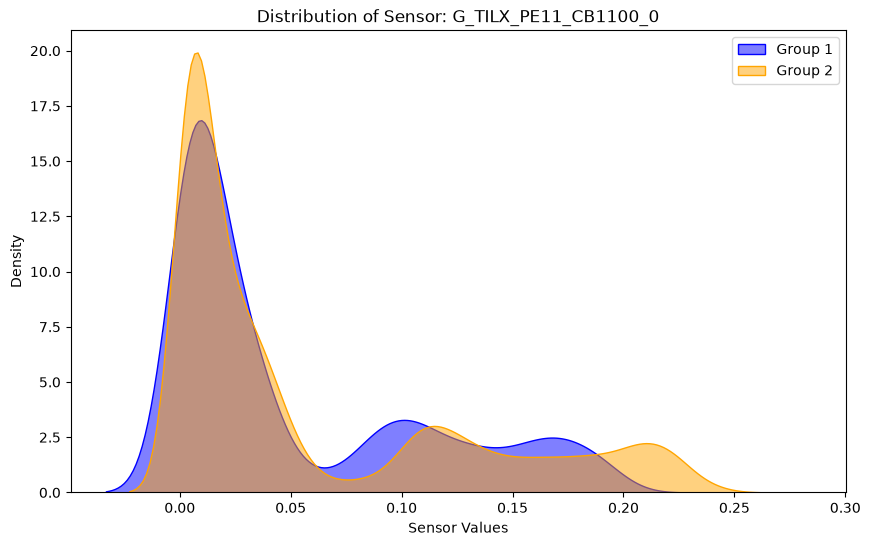

In [ ]:
# plot the distributions of the two groups for each sensor
for col in sensors_vehicle:
    if col == "Timestamp":
        continue
    df1 = df_grouped_1.query(f"Sensor == '{col}'").T.to_numpy()[1:,:].flatten().astype(float)
    df2 = df_grouped_2.query(f"Sensor == '{col}'").T.to_numpy()[1:,:].flatten().astype(float)
    
    df1 = np.abs(df1)
    df2 = np.abs(df2)
    
    plt.figure(figsize=(10, 6))
    sns.kdeplot(df1, label='Group 1', color='blue', fill=True, alpha=0.5)
    sns.kdeplot(df2, label='Group 2', color='orange', fill=True, alpha=0.5)
    plt.title(f"Distribution of Sensor: {col}")
    plt.xlabel("Sensor Values")
    plt.ylabel("Density")
    plt.legend()
    plt.show()

In [42]:
# path = "OpenLAB Data/2025_05_06_openLAB_tests/Data"
# file = path + '/MD_2025_05_06_09_08_25.txt'

# columns = [
#     "Zeit_1",
#     "DMS_1",
#     "Zeit_2",
#     "Kraft_N",
#     "Kraft_A",
#     "IWA",
#     "Temperatur_Bruecke",
#     "Temperatur_Umgebung",
#     "Zeit_3",
#     "LWA_1",
#     "LWA_2",
#     "LWA_3",
#     "Zeit_4",
#     "LWA_4",
#     "LWA_5",
#     "NMA_5",
#     "F_gesamt",
# ]

# # Read everything as strings first
# with open(file, encoding="latin1") as f:
#     lines = f.readlines()

# # Find first real measurement line
# start = next(
#     i for i, line in enumerate(lines)
#     if line.startswith("0\t")
# )

# # Get measurement lines
# rows = []

# for line in lines[start:]:
#     parts = line.rstrip("\r\n").split("\t")

#     # Only accept rows with exactly 17 values
#     if len(parts) == 17:
#         rows.append(parts)

# # DataFrame
# df = pd.DataFrame(rows, columns=columns)

# # Convert comma decimals to floats
# for col in df.columns:
#     df[col] = (
#         df[col]
#         .str.replace(",", ".", regex=False)
#         .astype(float)
#     )

# print(df.shape)
# print(df.head())
# print(df.dtypes)

# path = "OpenLAB Data/2025_05_06_openLAB_tests/Data"
# path + '/MD_2025_05_06_09_08_25.txt',
# dft = pd.read_csv(
#     path + '/MD_2025_05_06_09_08_25.txt',
#     sep="\t",
#     skiprows=36,       # adjust if necessary
#     decimal=",",
#     encoding="latin1",
#     header=None
# )

# dft.columns = columns
# dft = dft.drop(columns=["Extra"])
# dft.head()